# PA2 · Question 2 · Step 4: train model A (seeds 0 and 1) on a GPU

**What this notebook does.** It trains model A exactly as the handout's *Training and evaluation* section says. It saves the trained weights and a log file (losses, timings, hardware) for every seed. Later you will reuse the **same notebook** for models B, C and D: you only change one line in the CONFIG cell.

You write **one** small part (✏️ YOUR TURN): the **masked loss**. Everything else is provided, and every important piece has an automatic check.

### Kaggle settings (right-hand panel → *Settings*)
| Setting | Value |
|---|---|
| **Accelerator** | **GPU P100** or **GPU T4 x2** (one GPU is used) |
| **Internet** | **On** (data download) |

### How to run it (recommended)
1. **Interactively first**: keep `QUICK_TEST = True` in the CONFIG cell and click *Run All*. This runs a tiny version (a few videos, 1 epoch) in a minute or two and catches mistakes before you spend GPU time.
2. **Then for real**: set `QUICK_TEST = False`, click **Save Version → Save & Run All (Commit)**. Kaggle trains in the background; you can close the browser. When it finishes, the checkpoints and logs are in the version's **Output** tab.

### Two rules from the handout to remember
* **Q2.5** (your predictions for the mirror, rotation and speed tests) must be written and **committed to GitHub before Step 5** (testing). Training model A now is fine.
* **Q2.11** (your predictions for models B–D) must be committed **before you train B, C or D**.

In [1]:
import os, glob, json, time, math
import numpy as np
import torch, torchvision
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
HARDWARE = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print("torch", torch.__version__, "| device:", device, "|", HARDWARE)

torch 2.11.0+cu128 | device: cuda | Tesla T4


## 0. CONFIG: the only cell you normally change

In [2]:
#MODELS_TO_TRAIN = ["A"]     # now: ["A"].  Later (after committing Q2.11): ["B", "C"], then ["D"]
SEEDS           = [0, 1]    # the handout requires exactly these two seeds
EPOCHS          = 30        # handout: 30 epochs, keep the final-epoch weights
BATCH           = 32        # handout: batch size 32
LR              = 1e-3      # handout: Adam, learning rate 1e-3, no schedule
VAL_EVERY       = 5         # validation E(5) is printed every 5 epochs (monitoring only)
RUN_OVERFIT_TEST = True     # quick sanity test before the real training

# True = tiny run to test the code. Set to False for the real training.
#MODELS_TO_TRAIN = ["B", "C"]
MODELS_TO_TRAIN = ["D"]
#QUICK_TEST = True
QUICK_TEST = False  
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./outputs"
CKPT_DIR, LOG_DIR = os.path.join(OUT_DIR, "checkpoints"), os.path.join(OUT_DIR, "logs")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(LOG_DIR, exist_ok=True)

if QUICK_TEST:
    EPOCHS, VAL_EVERY = 1, 1
    print("QUICK_TEST is ON: tiny data, 1 epoch. Results are NOT valid for the report.")
if device.type != "cuda" and not QUICK_TEST:
    raise SystemExit("No GPU found. In Kaggle: Settings -> Accelerator -> GPU, then run again.")

## 1. Data, kept on the GPU

The whole dataset (10,000 videos as `uint8`, about 0.8 GB) is copied to the GPU **once**. Each batch is then cut directly on the GPU, which is much faster than a CPU data loader. Frames are converted to `float32 / 255` only when a batch is made.

In [3]:
ON_KAGGLE = os.path.exists("/kaggle/input")
DATA_ROOT = "/tmp/mmnist" if ON_KAGGLE else "./data"
found = glob.glob("/kaggle/input/**/mnist_test_seq.npy", recursive=True) if ON_KAGGLE else []
if found:
    os.makedirs(os.path.join(DATA_ROOT, "MovingMNIST"), exist_ok=True)
    link = os.path.join(DATA_ROOT, "MovingMNIST", "mnist_test_seq.npy")
    if not os.path.exists(link):
        os.symlink(found[0], link)
ds = torchvision.datasets.MovingMNIST(root=DATA_ROOT, split=None, download=True)
videos_u8 = ds.data if hasattr(ds, "data") else torch.stack([ds[i] for i in range(len(ds))])
assert tuple(videos_u8.shape) == (10000, 20, 1, 64, 64)

def to_float(v_u8):
    return v_u8.float() / 255.0

videos_dev = videos_u8.to(device)                  # uint8 on the GPU
train_dev, val_dev, test_dev = videos_dev[:8000], videos_dev[8000:9000], videos_dev[9000:]
if QUICK_TEST:
    train_dev, val_dev = train_dev[:64], val_dev[:64]
N_TRAIN = len(train_dev)
print("train / val / test videos:", N_TRAIN, len(val_dev), len(test_dev))

100%|██████████| 819M/819M [00:20<00:00, 40.4MB/s]


train / val / test videos: 8000 1000 1000


In [4]:
# ---- your Step 1 functions (checked in Table 1) ----
def mirror(x):
    return torch.flip(x, dims=[-1])

def rotate(x, a=1):
    return torch.rot90(x, k=a, dims=(-2, -1))

def make_window(video, t, k=1):
    in_nums  = [t + j*k for j in range(5)]
    out_nums = [t + j*k for j in range(5, 10)]
    X = video[[n - 1 for n in in_nums]]
    mask = torch.tensor([n <= 20 for n in out_nums])
    Y = torch.zeros(5, *video.shape[1:], dtype=video.dtype)
    for j, n in enumerate(out_nums):
        if n <= 20:
            Y[j] = video[n - 1]
    return X, Y, mask

G = [(a, m) for m in (0, 1) for a in range(4)]       # the 8 symmetries: (a, m) = M^m R^a

def apply_g(x, a, m):
    y = rotate(x, a)
    return mirror(y) if m else y

def apply_g_inverse(x, a, m):
    y = mirror(x) if m else x
    return rotate(y, -a)

In [5]:
# ---- your Step 3 model (all three checks were OK) ----
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, kernel_size=k, padding=k // 2, bias=True)

    def forward(self, u, h_prev, c_prev):
        z = self.conv(torch.cat([u, h_prev], dim=1))
        i, f, o, g = torch.chunk(z, 4, dim=1)
        c = torch.sigmoid(f) * c_prev + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c

class ModelA(nn.Module):
    def __init__(self, hid=64, patch=4):
        super().__init__()
        self.patch, self.hid = patch, hid
        C = patch * patch
        self.cell1 = ConvLSTMCell(C, hid)
        self.cell2 = ConvLSTMCell(hid, hid)
        self.head  = nn.Conv2d(hid, C, kernel_size=1, bias=True)

    def init_states(self, B, H, W, device):
        return [torch.zeros(B, self.hid, H, W, device=device) for _ in range(4)]

    def step(self, u, states):
        h1, c1, h2, c2 = states
        x = F.pixel_unshuffle(u, self.patch)
        h1, c1 = self.cell1(x, h1, c1)
        h2, c2 = self.cell2(h1, h2, c2)
        y = self.head(h2)
        pred = torch.sigmoid(F.pixel_shuffle(y, self.patch))
        return pred, [h1, c1, h2, c2]

    def forward(self, X):
        B, _, _, H, W = X.shape
        states = self.init_states(B, H // self.patch, W // self.patch, X.device)
        outputs, pred = [], None
        for tau in range(9):
            u = X[:, tau] if tau < 5 else pred
            pred, states = self.step(u, states)
            outputs.append(pred)
        return torch.stack(outputs[4:], dim=1)

class ModelD(ModelA):
    # D2: identical to model A, except layer 2's 3x3 convolution is dilated by 3.
    # Reach: 1 cell (layer 1) + 3 cells (layer 2) = 4 cells x 4 px = 16 px.  Parameters: 480,784 (same as A).
    def __init__(self, hid=64, patch=4, dilation=3):
        super().__init__(hid=hid, patch=patch)
        self.cell2.conv = nn.Conv2d(2 * hid, 4 * hid, kernel_size=3,
                                    padding=dilation, dilation=dilation, bias=True)

print("model D parameters:", sum(p.numel() for p in ModelD().parameters()))

SPECS = {   # which architecture, which training speeds, symmetry augmentation or not (handout model table)
    "A":  dict(arch="A", speeds=False, sym=False),
    "B":  dict(arch="A", speeds=False, sym=True),
    "C":  dict(arch="A", speeds=True,  sym=False),
    "D":  dict(arch="D", speeds=True,  sym=False),
    "DB": dict(arch="D", speeds=True,  sym=True),
}
def build_model(arch):
    return ModelA() if arch == "A" else ModelD()

print("model A parameters:", sum(p.numel() for p in ModelA().parameters()))

model D parameters: 480784
model A parameters: 480784


## 2. Background: the training protocol (from the handout)

| Item | What the handout says | Where it happens below |
|---|---|---|
| Optimiser | Adam, learning rate $10^{-3}$, no schedule | `train_one` |
| Batches and epochs | batch 32, **30 epochs**, keep the **final-epoch** weights (no early stopping) | `train_one` |
| One epoch | all 8,000 training videos in **shuffled** order, **one random window per video** | `sample_windows` |
| Windows for A and B | speed $1\times$, start $t \in \{1,\dots,11\}$ (all 5 targets exist) | `sample_windows` |
| Windows for C and D | speed $k$ uniform in $\{1,2,3\}$, then $t$ uniform over allowed starts ($t \le 20-6k$: 1–14, 1–8, 1–2) | `sample_windows` |
| Symmetry augmentation (B) | one $g$ uniform from the 8 elements of $G$, the **same** $g$ for input and target | `augment_symmetry` |
| Loss | squared error averaged over pixels and **available** target frames of each video, then averaged over the videos | **✏️ `masked_mse`** |
| Seeds | exactly 0 and 1; the seed controls initialisation, shuffling, window sampling and augmentation | `train_one` |
| Timing | mean wall-clock time per epoch over the 30 epochs; inference time for the 1,000 test videos at batch 32 | `train_one`, `time_inference` |

**How the seed controls everything here:** `torch.manual_seed(seed)` fixes the weight initialisation, and one `torch.Generator` seeded with the same number draws the shuffling, the windows and the symmetries. (GPU convolutions can still differ in the last few digits between runs; that is normal.)

## 3. Cutting windows for a whole batch at once (provided, checked against your `make_window`)

`windows_from_tk` does what your `make_window` does, but for many videos in one go and directly on the GPU: frame number $t + j\cdot k$ for $j = 0,\dots,9$, inputs are $j = 0..4$, targets are $j = 5..9$, and a target only exists if its frame number is $\le 20$.
The check below compares it with your Table-1-verified `make_window` on random videos, starts and speeds.

In [6]:
def windows_from_tk(vid_idx, videos, t, k):
    # vid_idx, t, k: 1D integer tensors of length B (CPU).  videos: (N,20,1,64,64) uint8 on the device.
    j = torch.arange(10)
    nums  = t[:, None] + j[None, :] * k[:, None]                 # frame numbers, (B, 10)
    valid = nums <= 20
    idx   = (nums.clamp(max=20) - 1).to(videos.device)           # tensor indices 0..19
    frames = videos[vid_idx.to(videos.device)[:, None], idx].float() / 255.0   # (B,10,1,64,64)
    mask = valid[:, 5:].to(videos.device)                        # (B, 5)
    X = frames[:, :5]
    Y = frames[:, 5:] * mask[:, :, None, None, None]             # missing targets -> zeros
    return X, Y, mask

def sample_windows(vid_idx, videos, gen, speeds):
    B = len(vid_idx)
    if speeds:                                                   # models C, D
        k = torch.randint(1, 4, (B,), generator=gen)             # k uniform in {1, 2, 3}
        tmax = 20 - 6 * k                                        # 14, 8, 2  (5 inputs + at least 2 targets)
        t = 1 + (torch.rand(B, generator=gen) * tmax).long()     # t uniform in 1..tmax
    else:                                                        # models A, B
        k = torch.ones(B, dtype=torch.long)
        t = torch.randint(1, 12, (B,), generator=gen)            # t uniform in 1..11
    return windows_from_tk(vid_idx, videos, t, k)

def augment_symmetry(X, Y, gen):
    # one g per window, uniform over the 8 elements of G, the SAME g for input and target
    g = torch.randint(0, 8, (X.shape[0],), generator=gen)
    Xo, Yo = X.clone(), Y.clone()
    for gi, (a, m) in enumerate(G):
        sel = (g == gi).nonzero().flatten().to(X.device)
        if len(sel):
            Xo[sel] = apply_g(X[sel], a, m)
            Yo[sel] = apply_g(Y[sel], a, m)
    return Xo, Yo

# ---------- check: batched windows == your make_window ----------
_gen = torch.Generator().manual_seed(123)
_ok = True
for _ in range(60):
    v = int(torch.randint(0, len(train_dev), (1,), generator=_gen))
    k = int(torch.randint(1, 4, (1,), generator=_gen))
    t = int(torch.randint(1, 20 - 6 * k + 1, (1,), generator=_gen))
    Xb, Yb, mb = windows_from_tk(torch.tensor([v]), train_dev, torch.tensor([t]), torch.tensor([k]))
    Xr, Yr, mr = make_window(to_float(train_dev[v].cpu()), t, k)
    _ok &= (torch.allclose(Xb[0].cpu(), Xr, atol=1e-6) and torch.allclose(Yb[0].cpu(), Yr, atol=1e-6)
        and torch.equal(mb[0].cpu(), mr))
# the speed rule must give at least 2 targets and all 5 inputs
Xs, Ys, ms = sample_windows(torch.arange(min(256, len(train_dev))) % len(train_dev), train_dev, _gen, speeds=True)
_ok &= bool((ms.sum(1) >= 2).all())
print("OK: batched windows match your make_window." if _ok else "FIX: batched windows do not match make_window.")
WINDOWS_OK = bool(_ok)

OK: batched windows match your make_window.


## 4. ✏️ YOUR TURN: the masked loss

**The handout's rule:** *squared error between prediction and target, averaged over the pixels and the **available** target frames of each video, then averaged over the videos in the batch. Every training video therefore contributes equally, whether it has two or five target frames.*

In three steps, for `Y_hat`, `Y` of shape `(B, 5, 1, 64, 64)` and `mask` of shape `(B, 5)`:

1. **Per frame:** average the squared error over the pixels, i.e. over the last three axes (channel, row, column). The result has shape `(B, 5)`.
2. **Per video:** average over the frames where `mask` is True only. Multiply by the mask, sum over the 5 frames, and divide by **how many frames are available in that video**. The result has shape `(B,)`.
3. **Per batch:** average over the videos. The result is one number.

**Why per video first?** Suppose video 1 has 5 targets and video 2 has only 2. If you pooled all 7 frames together, video 1 would count 2.5× more than video 2. Averaging per video first gives each video **equal weight**, as the handout requires.

**Skeleton:**
```python
se = (Y_hat - Y) ** 2                                    # squared error, (B,5,1,64,64)
mse_frame = se.mean(dim=( ___ ))                         # step 1 -> (B, 5)
m = mask.float()                                         # True/False -> 1.0/0.0
per_video = (mse_frame * ___ ).sum(dim=1) / ___          # step 2 -> (B,)
return per_video.mean()                                  # step 3 -> one number
```

In [7]:
def masked_mse(Y_hat, Y, mask):
    se = (Y_hat - Y) ** 2
    mse_frame = se.mean(dim=( -3,  -2, -1 ))       # the three pixel axes
    m = mask.float()
    per_video = (mse_frame * m ).sum(dim=1) / m .sum(dim=1)
    return per_video.mean()


# ---------- automatic check (do not edit) ----------
def check_loss():
    Y = torch.zeros(2, 5, 1, 4, 4); Y_hat = torch.zeros(2, 5, 1, 4, 4)
    for j, v in enumerate([0.1, 0.2, 0.3, 0.4, 0.5]):  # video 0: 5 available frames, errors 0.1..0.5
        Y[0, j] = v
    Y[1, 0], Y[1, 1] = 0.2, 0.4                        # video 1: only 2 available frames ...
    Y[1, 2:] = 0.9                                     # ... the other 3 hold junk that must be ignored
    mask = torch.tensor([[True] * 5, [True, True, False, False, False]])
    # expected: video 0 -> mean(0.01,0.04,0.09,0.16,0.25) = 0.11 ; video 1 -> mean(0.04,0.16) = 0.10 ; loss = 0.105
    got = float(masked_mse(Y_hat, Y, mask))
    if abs(got - 0.105) < 1e-6:
        print(f"OK: masked_mse = {got:.6f} (expected 0.105000)")
        return True
    hints = {0.107143: "you pooled all available frames together; average PER VIDEO first (divide by each video's own count)",
             0.318000: "the missing frames were not ignored: multiply by the mask and divide by the number of available frames",
             0.712500: "multiply mse_frame by the mask before summing, so the missing frames count as 0",
             0.075000: "you divided by 5 for every video; divide by the number of AVAILABLE frames (m.sum(dim=1))"}
    hint = next((h for v, h in hints.items() if abs(got - v) < 1e-4), "compare your three steps with the skeleton")
    print(f"FIX: masked_mse = {got:.6f}, expected 0.105000. Hint: {hint}")
    return False

try:
    LOSS_OK = check_loss()
except NotImplementedError:
    LOSS_OK = False
    print("masked_mse not written yet.")

OK: masked_mse = 0.105000 (expected 0.105000)


## 5. Evaluation and timing helpers (provided; Step 5 reuses them)

* `per_video_mse(...)` returns, for every video, the MSE of each forecast horizon $h = 1..5$: an array of shape `(N, 5)`, with `NaN` where the target frame does not exist. From it: $E^{(5)}$ = mean over the 5 horizons, $E^{(2)}$ = mean over the first two, each then averaged over the videos.
* **Blank** predicts all-zero frames; **Copy-last** repeats the last input frame.
* `time_inference(...)` follows the handout: the 1,000 original test videos ($1\times$, $t=1$), batch 32, `model.eval()` and `torch.no_grad()`, timing only the model's work after each batch is on the device. One warm-up batch runs first and is not timed.

In [8]:
def predict_blank(X):
    return torch.zeros(X.shape[0], 5, *X.shape[2:], device=X.device)

def predict_copy_last(X):
    return X[:, 4:5].expand(-1, 5, -1, -1, -1)

@torch.no_grad()
def per_video_mse(predict, videos, k=1, t=1, batch=32):
    # predict: a model or a function mapping X (B,5,1,64,64) -> Y_hat (B,5,1,64,64)
    if isinstance(predict, nn.Module):
        predict.eval()
    out = []
    for b in range(0, len(videos), batch):
        vid = torch.arange(b, min(b + batch, len(videos)))
        X, Y, mask = windows_from_tk(vid, videos, torch.full((len(vid),), t), torch.full((len(vid),), k))
        Y_hat = predict(X)
        mse = ((Y_hat - Y) ** 2).mean(dim=(2, 3, 4))          # (B, 5)
        mse[~mask] = float("nan")
        out.append(mse.cpu())
    return torch.cat(out).numpy()

def E5(m): return float(np.nanmean(m[:, :5].mean(axis=1)))
def E2(m): return float(np.nanmean(m[:, :2].mean(axis=1)))

@torch.no_grad()
def time_inference(model, videos, batch=32):
    model.eval()
    def batch_X(b):
        vid = torch.arange(b, min(b + batch, len(videos)))
        X, _, _ = windows_from_tk(vid, videos, torch.ones(len(vid), dtype=torch.long), torch.ones(len(vid), dtype=torch.long))
        return X
    model(batch_X(0))                                          # warm-up (not timed)
    total = 0.0
    for b in range(0, len(videos), batch):
        X = batch_X(b)                                         # batch is already on the device
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        model(X)
        if device.type == "cuda": torch.cuda.synchronize()
        total += time.perf_counter() - t0
    return total

copy_val = E5(per_video_mse(predict_copy_last, val_dev))
blank_val = E5(per_video_mse(predict_blank, val_dev))
print(f"validation E(5) (1x, t=1):  Blank {blank_val:.4g}   Copy-last {copy_val:.4g}")

validation E(5) (1x, t=1):  Blank 0.04182   Copy-last 0.06328


## 6. Overfit test (a 1-minute sanity check)

A correct model and loss must be able to **memorise** a tiny dataset. We train a fresh model A on 32 fixed windows for 150 steps. The loss should fall clearly (to well below half of its starting value). If it does not, something is wrong, and it is better to find out now than after hours of training.

In [9]:
def overfit_test(steps=150):
    torch.manual_seed(999)
    model = ModelA().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    vid = torch.arange(min(32, len(train_dev)))
    X, Y, mask = windows_from_tk(vid, train_dev, torch.ones(len(vid), dtype=torch.long), torch.ones(len(vid), dtype=torch.long))
    losses = []
    for s in range(steps):
        loss = masked_mse(model(X), Y, mask)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        losses.append(loss.item())
    print(f"overfit test: loss {losses[0]:.4f} -> {losses[-1]:.4f}  "
          f"({'OK' if losses[-1] < 0.5 * losses[0] else 'CHECK: the loss did not fall much'})")
    return losses

if not (LOSS_OK and WINDOWS_OK):
    raise SystemExit("Fix masked_mse (and the window check) before going on.")
if RUN_OVERFIT_TEST:
    _ = overfit_test(steps=20 if QUICK_TEST else 150)

overfit test: loss 0.2436 -> 0.0414  (OK)


## 7. The training function (provided)

For each epoch it shuffles the training videos, draws one window per video (and a symmetry for model B), trains on batches of 32, and records:
* the mean training loss of the epoch,
* the **wall-clock time** of the training pass (GPU synchronised before and after; validation is **not** included in this time),
* every `VAL_EVERY` epochs, the validation $E^{(5)}$ at $1\times$ (monitoring only: it never changes the training).

After the last epoch it saves the final weights, measures the inference time, and writes a JSON log.

In [10]:
def train_one(name, seed):
    spec = SPECS[name]
    torch.manual_seed(seed); np.random.seed(seed)
    gen = torch.Generator().manual_seed(seed)        # shuffling, windows, symmetries
    model = build_model(spec["arch"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    log = dict(model=name, seed=seed, epochs=EPOCHS, batch=BATCH, lr=LR, n_params=n_params,
               hardware=HARDWARE, torch=torch.__version__, quick_test=QUICK_TEST,
               epoch_time_s=[], epoch_train_loss=[], val_E5={})
    print(f"\n=== model {name}, seed {seed}: {n_params:,} parameters, {EPOCHS} epochs on {HARDWARE} ===")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(N_TRAIN, generator=gen)
        running = torch.zeros((), device=device)
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        for b in range(0, N_TRAIN, BATCH):
            vid = perm[b:b + BATCH]
            X, Y, mask = sample_windows(vid, train_dev, gen, spec["speeds"])
            if spec["sym"]:
                X, Y = augment_symmetry(X, Y, gen)
            loss = masked_mse(model(X), Y, mask)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            running += loss.detach() * len(vid)
        if device.type == "cuda": torch.cuda.synchronize()
        log["epoch_time_s"].append(time.perf_counter() - t0)
        log["epoch_train_loss"].append(float(running) / N_TRAIN)
        msg = f"epoch {epoch:2d}/{EPOCHS}  train loss {log['epoch_train_loss'][-1]:.5f}  time {log['epoch_time_s'][-1]:.1f}s"
        if epoch % VAL_EVERY == 0 or epoch == EPOCHS:
            v = E5(per_video_mse(model, val_dev))
            log["val_E5"][epoch] = v
            msg += f"  | val E(5) {v:.5f} (Copy-last {copy_val:.5f})"
        print(msg, flush=True)
    log["train_time_per_epoch_s"] = float(np.mean(log["epoch_time_s"]))
    log["inference_time_s"] = time_inference(model, test_dev if not QUICK_TEST else test_dev[:64])
    ckpt = os.path.join(CKPT_DIR, f"{name}_seed{seed}.pt")
    torch.save(model.state_dict(), ckpt)
    with open(os.path.join(LOG_DIR, f"{name}_seed{seed}.json"), "w") as f:
        json.dump(log, f, indent=1)
    print(f"saved {ckpt}  | mean epoch time {log['train_time_per_epoch_s']:.1f}s  | inference {log['inference_time_s']:.2f}s")
    return log

## 8. Train (this is the long part)

With `QUICK_TEST = False` this trains every model in `MODELS_TO_TRAIN` with seeds 0 and 1, one after the other. On a P100 or T4, my rough estimate is 10–20 minutes per seed; the first epoch's printed time tells you the real speed.

In [11]:
all_logs = {}
for name in MODELS_TO_TRAIN:
    for seed in SEEDS:
        all_logs[(name, seed)] = train_one(name, seed)
print("\nALL TRAINING DONE.")


=== model D, seed 0: 480,784 parameters, 30 epochs on Tesla T4 ===
epoch  1/30  train loss 0.04647  time 14.1s
epoch  2/30  train loss 0.04013  time 14.3s
epoch  3/30  train loss 0.03990  time 14.6s
epoch  4/30  train loss 0.03952  time 15.0s
epoch  5/30  train loss 0.03916  time 15.2s  | val E(5) 0.03832 (Copy-last 0.06328)
epoch  6/30  train loss 0.03882  time 14.8s
epoch  7/30  train loss 0.03840  time 14.6s
epoch  8/30  train loss 0.03811  time 14.7s
epoch  9/30  train loss 0.03739  time 14.8s
epoch 10/30  train loss 0.03678  time 14.9s  | val E(5) 0.03544 (Copy-last 0.06328)
epoch 11/30  train loss 0.03632  time 14.9s
epoch 12/30  train loss 0.03601  time 14.8s
epoch 13/30  train loss 0.03580  time 14.8s
epoch 14/30  train loss 0.03546  time 14.8s
epoch 15/30  train loss 0.03507  time 14.8s  | val E(5) 0.03292 (Copy-last 0.06328)
epoch 16/30  train loss 0.03468  time 14.8s
epoch 17/30  train loss 0.03432  time 14.8s
epoch 18/30  train loss 0.03410  time 14.8s
epoch 19/30  train l

## 9. Summary of this run (just run)

The table prints the numbers you will need for Tables 2 and 5: parameters, mean training time per epoch, inference time, hardware. The plot shows the training loss per epoch for each seed (both seeds should look similar and go down).

model  seed    params   s/epoch  infer (s)  final loss   val E(5)   hardware
D         0   480,784      14.8       0.62     0.03140    0.02871   Tesla T4
D         1   480,784      14.8       0.61     0.03049    0.02767   Tesla T4


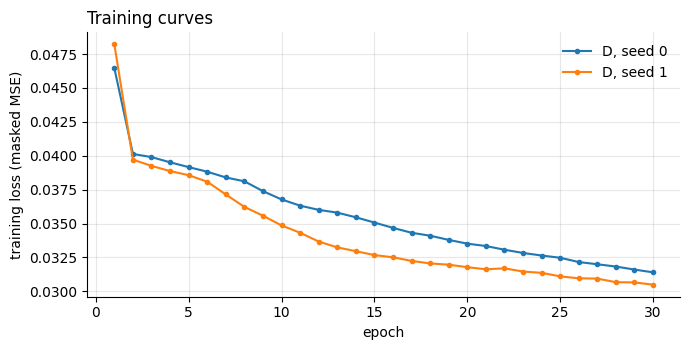

Files in /kaggle/working : ['D_seed0.pt', 'D_seed1.pt'] ['D_seed0.json', 'D_seed1.json']


In [12]:
print(f"{'model':<6}{'seed':>5}{'params':>10}{'s/epoch':>10}{'infer (s)':>11}{'final loss':>12}{'val E(5)':>11}   hardware")
for (name, seed), lg in all_logs.items():
    last_val = list(lg["val_E5"].values())[-1]
    print(f"{name:<6}{seed:>5}{lg['n_params']:>10,}{lg['train_time_per_epoch_s']:>10.1f}{lg['inference_time_s']:>11.2f}"
          f"{lg['epoch_train_loss'][-1]:>12.5f}{last_val:>11.5f}   {lg['hardware']}")

fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, seed), lg in all_logs.items():
    ax.plot(range(1, len(lg["epoch_train_loss"]) + 1), lg["epoch_train_loss"], marker="o", ms=3, label=f"{name}, seed {seed}")
ax.set_xlabel("epoch"); ax.set_ylabel("training loss (masked MSE)"); ax.set_title("Training curves", loc="left")
ax.grid(alpha=0.3); ax.legend(frameon=False)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=150); plt.show()
print("Files in", OUT_DIR, ":", sorted(os.listdir(CKPT_DIR)), sorted(os.listdir(LOG_DIR)))

## 10. After the real run finishes

1. Open the saved version → **Output** tab. You should see `checkpoints/A_seed0.pt`, `checkpoints/A_seed1.pt`, `logs/A_seed0.json`, `logs/A_seed1.json` and `training_curves.png`.
2. **Before Step 5:** write your **Q2.5 predictions** (mirror test? rotation test? at what speed should model A break down, given your reach estimate and Figure 1?) and **commit them to GitHub**. Step 5 runs those tests.
3. **While the GPU trains**, good uses of your time: work out the reach for **Q2.3**, and start the **Q1** report (assumptions and diagram).
4. In Step 5 you will load these checkpoints by adding this notebook's output as input data (*Add Input → Your Work → this notebook*).